In [28]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, roc_auc_score

In [29]:
def set_korean_font():
    import platform
    system_name = platform.system()
    if system_name == 'Windows':
        plt.rc('font', family='Malgun Gothic')
    elif system_name == 'Darwin':  # macOS
        plt.rc('font', family='AppleGothic')
    else:  # Linux / Colab
        plt.rc('font', family='NanumBarunGothic')
    plt.rcParams['axes.unicode_minus'] = False

set_korean_font()

In [30]:
df_raw = pd.read_excel('2026_분석용데이터(24년부터).xlsx')

In [31]:
df = df_raw[df_raw['year'] == 2026].copy()

In [32]:
print(len(df))

313


In [33]:
#psychographics variable

df['gen_label'] = df['gen'].map({1: '남성', 2: '여성'})
df['grade_grp'] = pd.cut(df['grade'], bins=[0, 2, 4], labels=['저학년(1-2학년)', '고학년(3-4학년)'])
df['housing_grp'] = df['d3'].map({1: '기숙사', 2: '자취', 3: '통학', 4: '기타'})
df['allowance_grp'] = pd.cut(df['d2'], bins=[0, 3, 5, 9], labels=['30만원 이하', '31~50만원', '51만원 이상'])
df['commute_grp'] = pd.cut(df['d5'], bins=[-1, 29, 59, 999], labels=['30분 미만', '30분~1시간 미만', '1시간 이상'])

In [34]:
# 만족도 이진화 변수 (5점 이상 만족=1)
df['sat_binary'] = (df['a6'] >= 5).astype(int)
df['sat_label'] = df['sat_binary'].map({1: '만족(5점 이상)', 0: '비만족(4점 이하)'})

# 가격 민감도 및 갭(Gap) 변수
df['Price_Gap_Ext'] = df['a27'] - df['b1']     # 외부 점심값 대비 절감 가치 (+)
df['Price_Gap_Fair'] = df['b2'] - df['b1']    # 적정가 대비 수용 저항 (-)
df['Price_Gap_Margin'] = df['b3'] - df['b2']  # 메뉴 개선 시 가격 인상 여유 폭
df['Price_Gap_Limit'] = df['b3'] - df['b1']   # 최대 지출 여유 폭

# 컬럼 정의 (b4~b20: 만족도, b21~b37: 중요도)
sat_cols = [f'b{i}' for i in range(4, 21)]
imp_cols = [f'b{i}' for i in range(21, 38)]
attr_names = [
    '메뉴 다양성', '메뉴 가격', '메뉴 영양', '음식 맛', '음식 양',
    '주재료 양', '음식 신선도', '배식 대기시간', '키오스크 대기시간', '품절 방지',
    '식사 공간 다양성', '인테리어 분위기', '매장 레이아웃', '조명 색/밝기', '매장 청결/위생',
    '무인주문기 편리성', '식당 접근성'
]

In [35]:
df.to_csv('2026_univ_data_recoded.csv', index= False, encoding = 'utf-8-sig')

In [42]:
print("[Step 3] KMO 적합도 검정 및 탐색적 요인분석 (EFA)")
print("="*60)

def calculate_kmo(df_features):
    corr = df_features.corr().values
    inv_corr = np.linalg.inv(corr)
    n = corr.shape[0]
    partial_corr = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            partial_corr[i, j] = -inv_corr[i, j] / np.sqrt(inv_corr[i, i] * inv_corr[j, j])
            partial_corr[j, i] = partial_corr[i, j]
    sum_r2 = np.sum(corr**2) - np.sum(np.diag(corr**2))
    sum_p2 = np.sum(partial_corr**2)
    return sum_r2 / (sum_r2 + sum_p2)

kmo_val = calculate_kmo(df[sat_cols])
print(f"· KMO 표본 적합도 (Kaiser-Meyer-Olkin): {kmo_val:.3f} (0.8 이상으로 매우 우수)")


[Step 3] KMO 적합도 검정 및 탐색적 요인분석 (EFA)
· KMO 표본 적합도 (Kaiser-Meyer-Olkin): 0.858 (0.8 이상으로 매우 우수)


In [37]:
# PCA를 활용한 3개 요인 추출
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[sat_cols])

pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)
cum_var = np.sum(pca.explained_variance_ratio_) * 100

print(f"· 3개 추출 요인의 누적 설명 분산 비율: {cum_var:.2f}%")
for i, ratio in enumerate(pca.explained_variance_ratio_):
    print(f"  - 요인 {i+1} 설명력: {ratio*100:.2f}%")

· 3개 추출 요인의 누적 설명 분산 비율: 53.57%
  - 요인 1 설명력: 33.50%
  - 요인 2 설명력: 11.27%
  - 요인 3 설명력: 8.80%


In [38]:
# ==========================================
# 4. OLS 다중 회귀분석 (N=313 검증)
# ==========================================
print("\n" + "="*60)
print("[Step 4] OLS 다중 회귀분석 (종속변수: 전반적 만족도 a6)")
print("="*60)

X_ols = sm.add_constant(df[sat_cols])
y_ols = df['a6']
ols_model = sm.OLS(y_ols, X_ols).fit()

print(f"· 결정계수 (R-squared): {ols_model.rsquared:.3f}")
print(f"· 수정 결정계수 (Adj. R-squared): {ols_model.rsquared_adj:.3f}")
print("-" * 60)
print("주요 유의 변수 (p < 0.05) 계수:")
for var, val, pval in zip(sat_cols, ols_model.params[1:], ols_model.pvalues[1:]):
    if pval < 0.05:
        idx = int(var.replace('b', '')) - 4
        print(f"  · {attr_names[idx]} ({var}): 계수 = {val:.3f} (p-value = {pval:.4f})")


[Step 4] OLS 다중 회귀분석 (종속변수: 전반적 만족도 a6)
· 결정계수 (R-squared): 0.466
· 수정 결정계수 (Adj. R-squared): 0.435
------------------------------------------------------------
주요 유의 변수 (p < 0.05) 계수:
  · 메뉴 다양성 (b4): 계수 = 0.125 (p-value = 0.0114)
  · 메뉴 가격 (b5): 계수 = 0.158 (p-value = 0.0016)
  · 음식 맛 (b7): 계수 = 0.383 (p-value = 0.0000)
  · 음식 신선도 (b10): 계수 = 0.182 (p-value = 0.0037)
  · 매장 레이아웃 (b16): 계수 = 0.114 (p-value = 0.0372)
  · 식당 접근성 (b20): 계수 = 0.102 (p-value = 0.0303)


In [ ]:
# ==========================================
# 5. K-Means 군집분석 (요인점수 기반 다중공선성 해소)
# ==========================================
print("\n" + "="*60)
print("[Step 5] K-Means 군집분석 및 세분시장 프로파일링 (k=3)")
print("="*60)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_pca)  # PCA 요인 점수 입력으로 다중공선성 해소

# 군집 라벨 매핑 (만족도 및 특성 기반)
cluster_profile_temp = df.groupby('cluster')['a6'].mean()
# 만족도 순서에 따른 매핑 규칙 적용
cluster_map = {0: '실속형', 2: '품질형', 1: '편의형'}
df['cluster_label'] = df['cluster'].map(cluster_map)

profile = df.groupby('cluster_label').agg(
    인원수=('a6', 'count'),
    시장비중=('a6', lambda x: f"{len(x)/len(df)*100:.1f}%"),
    a6_만족도평균=('a6', 'mean'),
    a6_만족률=('sat_binary', lambda x: f"{x.mean()*100:.1f}%"),
    체감적정가_b2=('b2', 'mean'),
    가격저항_Gap=('Price_Gap_Fair', 'mean')
).reindex(['실속형', '품질형', '편의형'])

print(profile)




[Step 5] K-Means 군집분석 및 세분시장 프로파일링 (k=3)
               인원수   시장비중  a6_만족도평균 a6_만족률    체감적정가_b2    가격저항_Gap
cluster_label                                                     
실속형             80  25.6%  5.012500  65.0%  5631.25000 -526.250000
품질형            118  37.7%  3.635593  16.1%  5335.59322 -837.288136
편의형            115  36.7%  4.547826  50.4%  5420.00000 -802.608696
['year', 'id', 'age', 'gen', 'grade', 'nat', 'a1', 'a2', 'a1_1', 'a3', 'a4', 'a5', 'a6', 'a7', 'a8', 'a9', 'a10', 'a11', 'a12', 'a13', 'a14', 'a13_1', 'a15', 'a16', 'a15_1', 'a17', 'a18', 'a19', 'a20', 'a21', 'a22', 'a23', 'a24', 'a25', 'a26', 'a27', 'b1', 'b2', 'b3', 'b4', 'b5', 'b6', 'b7', 'b8', 'b9', 'b10', 'b11', 'b12', 'b13', 'b14', 'b15', 'b16', 'b17', 'b18', 'b19', 'b20', 'b21', 'b22', 'b23', 'b24', 'b25', 'b26', 'b27', 'b28', 'b29', 'b30', 'b31', 'b32', 'b33', 'b34', 'b35', 'b36', 'b37', 'b38', 'b39', 'b40', 'b41', 'b42', 'b43', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9', 'c10', 'c11', 'c12', 'c13'

c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [46]:
# 생략(...) 없이 모든 행 출력하도록 설정
pd.set_option('display.max_rows', None)

# 설문 주요 문항(a, b, c)만 군집별 평균 출력
target_cols = [col for col in df.columns if col.startswith(('a', 'b', 'c')) and col not in ['age', 'allowance_grp', 'commute_grp', 'cluster', 'cluster_label']]
print(df.groupby('cluster_label')[target_cols].mean(numeric_only=True).round(2).T)

cluster_label      실속형      편의형      품질형
a1                4.54     4.51     5.33
a2                4.62     4.76     4.38
a3                5.18     5.04     4.65
a4                1.62     1.57     1.21
a5                4.59     3.97     4.11
a6                5.01     4.55     3.64
a7                4.34     4.13     4.34
a8                5.20     4.64     4.22
a9                5.24     4.90     4.01
a10               5.24     4.84     4.02
a11               4.92     4.63     4.24
a12               5.76     5.19     4.94
a13               4.88     4.70     4.65
a14               4.80     4.88     4.57
a15               4.03     4.03     3.98
a16               4.34     5.10     4.43
a17               4.46     3.97     3.39
a18               0.90     0.90     0.86
a19               0.81     0.77     0.70
a20               0.19     0.16     0.35
a21               0.28     0.27     0.15
a22               0.32     0.29     0.44
a23               0.55     0.61     0.73
a24             

In [ ]:
f_a6, p_a6 = stats.f_oneway(*[g['a6'].values for _, g in df.groupby('cluster_label')])
f_gap, p_gap = stats.f_oneway(*[g['Price_Gap_Fair'].values for _, g in df.groupby('cluster_label')])

print(f"\n[ANOVA 일원배치 분산분석 결과]")
print(f"· 만족도(a6) 군집 간 차이: F = {f_a6:.3f}, p-value = {p_a6:.4e} (유의함)")
print(f"· 가격 저항(b2-b1) 군집 간 차이: F = {f_gap:.3f}, p-value = {p_gap:.4f} (유의함)")


[ANOVA 일원배치 분산분석 결과]
· 만족도(a6) 군집 간 차이: F = 47.241, p-value = 1.2350e-18 (유의함)
· 가격 저항(b2-b1) 군집 간 차이: F = 3.761, p-value = 0.0243 (유의함)


In [ ]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# ==========================================
# 5-1. ANOVA 사후검증 (Tukey HSD Test)
# ==========================================
print("\n" + "="*60)
print("[Step 5-1] 일원분산분석(ANOVA) 사후검증 (Tukey's HSD)")
print("="*60)

# 1) 전반적 만족도(a6) 집단 간 사후검증
tukey_a6 = pairwise_tukeyhsd(endog=df['a6'], groups=df['cluster_label'], alpha=0.05)
print("[1. 만족도(a6) 군집 간 쌍별 비교]")
print(tukey_a6)

# 2) 가격 저항(Price_Gap_Fair) 집단 간 사후검증
tukey_gap = pairwise_tukeyhsd(endog=df['Price_Gap_Fair'], groups=df['cluster_label'], alpha=0.05)
print("\n[2. 체감 가격 저항(Price_Gap_Fair) 군집 간 쌍별 비교]")
print(tukey_gap)


[Step 5-1] 일원분산분석(ANOVA) 사후검증 (Tukey's HSD)
[1. 만족도(a6) 군집 간 쌍별 비교]
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   실속형    편의형  -0.4647 0.0058 -0.8167 -0.1126   True
   실속형    품질형  -1.3769    0.0 -1.7271 -1.0267   True
   편의형    품질형  -0.9122    0.0 -1.2291 -0.5954   True
----------------------------------------------------

[2. 체감 가격 저항(Price_Gap_Fair) 군집 간 쌍별 비교]
  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower    upper   reject
--------------------------------------------------------
   실속형    편의형 -276.3587 0.0602 -561.8528   9.1354  False
   실속형    품질형 -311.0381 0.0279 -595.0394 -27.0369   True
   편의형    품질형  -34.6794 0.9458 -291.6372 222.2783  False
--------------------------------------------------------


In [47]:
print("=== 1. 기초통계량 확인 (만족도 4.32점 / 실제 지불액 6,184원) ===")
print(f"전반적 만족도(a6) 평균: {df['a6'].mean():.2f}점")
print(f"현재 전체 만족률(sat_binary): {df['sat_binary'].mean()*100:.1f}%")
print(f"실제 지불액(b1) 평균: {df['b1'].mean():.0f}원")
print(f"체감 적정가(b2) 평균: {df['b2'].mean():.0f}원")

print("\n=== 2. +1,200원 WTP(추가 지불의향액) 근거 확인 ===")
print(f"시그니처형 적정가(c18) 평균: {df['c18'].mean():.0f}원 (기존 적정가 b2 대비 +{df['c18'].mean() - df['b2'].mean():.0f}원)")
print(f"푸드코트형 적정가(c15) 평균: {df['c15'].mean():.0f}원 (기존 적정가 b2 대비 +{df['c15'].mean() - df['b2'].mean():.0f}원)")
print(f"만족 집단 vs 비만족 집단 적정가(b2) 차이: {df.groupby('sat_binary')['b2'].mean().diff().iloc[-1]:.0f}원")

print("\n=== 3. 만족률 70%+ 도약 근거 확인 (맛 4.5점 이상 집단) ===")
high_taste = df[df['b7'] >= 4.5]
print(f"음식 맛(b7) 4.5점 이상 집단(n={len(high_taste)})의 실제 만족률: {high_taste['sat_binary'].mean()*100:.1f}%")

=== 1. 기초통계량 확인 (만족도 4.32점 / 실제 지불액 6,184원) ===
전반적 만족도(a6) 평균: 4.32점
현재 전체 만족률(sat_binary): 41.2%
실제 지불액(b1) 평균: 6187원
체감 적정가(b2) 평균: 5442원

=== 2. +1,200원 WTP(추가 지불의향액) 근거 확인 ===
시그니처형 적정가(c18) 평균: 6201원 (기존 적정가 b2 대비 +758원)
푸드코트형 적정가(c15) 평균: 7411원 (기존 적정가 b2 대비 +1968원)
만족 집단 vs 비만족 집단 적정가(b2) 차이: -7원

=== 3. 만족률 70%+ 도약 근거 확인 (맛 4.5점 이상 집단) ===
음식 맛(b7) 4.5점 이상 집단(n=111)의 실제 만족률: 71.2%


In [ ]:
# ==========================================
# 6. 로지스틱 회귀 및 의사결정나무 분석
# ==========================================
print("\n" + "="*60)
print("[Step 6] 로지스틱 회귀분석 및 의사결정나무 (Decision Tree)")
print("="*60)

clf = LogisticRegression(random_state=42, max_iter=1000)
clf.fit(df[sat_cols], df['sat_binary'])

y_pred = clf.predict(df[sat_cols])
y_prob = clf.predict_proba(df[sat_cols])[:, 1]

print(f"· 로지스틱 분류 정확도 (Accuracy): {accuracy_score(df['sat_binary'], y_pred)*100:.1f}%")
print(f"· ROC-AUC: {roc_auc_score(df['sat_binary'], y_prob):.3f}")

coef_df = pd.DataFrame({
    '속성명': attr_names,
    'Logit계수': clf.coef_[0],
    'Odds_Ratio': np.exp(clf.coef_[0])
}).sort_values('Logit계수', ascending=False)

print("\n[상위 주요 영향 요인 Odds Ratio]")
print(coef_df.head(4).to_string(index=False))

# Decision Tree 규칙 출력 및 세부 노드 집계
dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(df[sat_cols], df['sat_binary'])

print("\n[Decision Tree 분기 규칙]")
print(export_text(dt_model, feature_names=attr_names))

# 특정 노드 (음식 맛 <= 4.50 미달 그룹) 세부 통계 계산
sub_group = df[df['b7'] <= 4.5]
print(f"· [PPT Slide 7 검증] 음식 맛 4.5점 미달 그룹 (n={len(sub_group)}명) 만족률: {sub_group['sat_binary'].mean()*100:.1f}%")


[Step 6] 로지스틱 회귀분석 및 의사결정나무 (Decision Tree)
· 로지스틱 분류 정확도 (Accuracy): 76.4%
· ROC-AUC: 0.830

[상위 주요 영향 요인 Odds Ratio]
   속성명  Logit계수  Odds_Ratio
  음식 맛 0.755003    2.127617
음식 신선도 0.507787    1.661609
메뉴 다양성 0.286126    1.331260
 메뉴 가격 0.264094    1.302251

[Decision Tree 분기 규칙]
|--- 음식 맛 <= 4.50
|   |--- 음식 신선도 <= 4.50
|   |   |--- 메뉴 가격 <= 4.50
|   |   |   |--- class: 0
|   |   |--- 메뉴 가격 >  4.50
|   |   |   |--- class: 0
|   |--- 음식 신선도 >  4.50
|   |   |--- 매장 레이아웃 <= 5.50
|   |   |   |--- class: 0
|   |   |--- 매장 레이아웃 >  5.50
|   |   |   |--- class: 1
|--- 음식 맛 >  4.50
|   |--- 메뉴 다양성 <= 3.50
|   |   |--- 매장 청결/위생 <= 4.50
|   |   |   |--- class: 1
|   |   |--- 매장 청결/위생 >  4.50
|   |   |   |--- class: 0
|   |--- 메뉴 다양성 >  3.50
|   |   |--- 음식 양 <= 1.50
|   |   |   |--- class: 0
|   |   |--- 음식 양 >  1.50
|   |   |   |--- class: 1

· [PPT Slide 7 검증] 음식 맛 4.5점 미달 그룹 (n=202명) 만족률: 24.8%



[Step 7] IPA 매트릭스 집계 및 시각화 생성


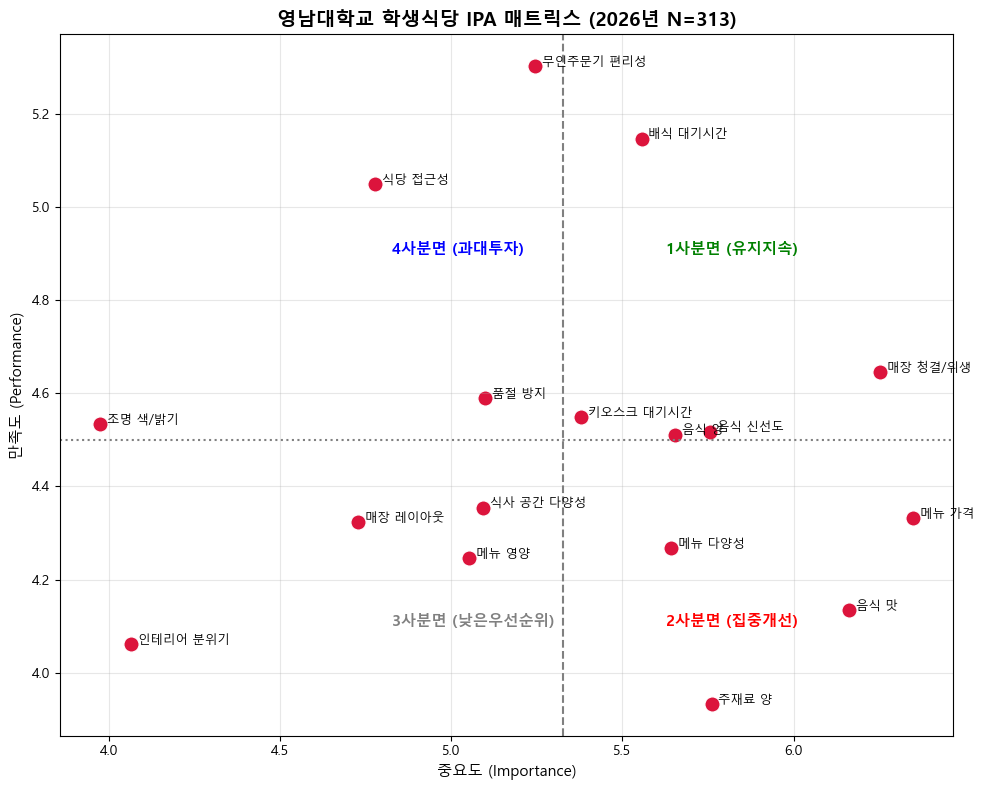

In [ ]:
# ==========================================
# 7. IPA (Importance-Performance Analysis) 매트릭스
# ==========================================
print("\n" + "="*60)
print("[Step 7] IPA 매트릭스 집계 및 시각화 생성")
print("="*60)

sat_means = df[sat_cols].mean().values
imp_means = df[imp_cols].mean().values
sat_cutoff = sat_means.mean()  # 4.50
imp_cutoff = imp_means.mean()  # 5.33

ipa_df = pd.DataFrame({
    'item_name': attr_names,
    'satisfaction': sat_means,
    'importance': imp_means
})

# IPA Plot 시각화
plt.figure(figsize=(10, 8))
sns.scatterplot(data=ipa_df, x='importance', y='satisfaction', s=120, color='crimson')

plt.axvline(x=imp_cutoff, color='gray', linestyle='--', label=f'중요도 평균 ({imp_cutoff:.2f})')
plt.axhline(y=sat_cutoff, color='gray', linestyle=':', label=f'만족도 평균 ({sat_cutoff:.2f})')

for i, row in ipa_df.iterrows():
    plt.text(row['importance'] + 0.02, row['satisfaction'], row['item_name'], fontsize=9)

plt.text(imp_cutoff + 0.3, sat_cutoff + 0.4, '1사분면 (유지지속)', fontsize=11, fontweight='bold', color='green')
plt.text(imp_cutoff + 0.3, sat_cutoff - 0.4, '2사분면 (집중개선)', fontsize=11, fontweight='bold', color='red')
plt.text(imp_cutoff - 0.5, sat_cutoff - 0.4, '3사분면 (낮은우선순위)', fontsize=11, fontweight='bold', color='gray')
plt.text(imp_cutoff - 0.5, sat_cutoff + 0.4, '4사분면 (과대투자)', fontsize=11, fontweight='bold', color='blue')

plt.title("영남대학교 학생식당 IPA 매트릭스 (2026년 N=313)", fontsize=14, fontweight='bold')
plt.xlabel("중요도 (Importance)", fontsize=11)
plt.ylabel("만족도 (Performance)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('IPA_Matrix_2026.png', dpi=300)
plt.show()

In [ ]:
# ==========================================
# 8. 가격 갭 & 푸드코트형(신규 유형) 집계 모듈 (Slide 2 & 8 보완)
# ==========================================
print("\n" + "="*60)
print("[Step 8] 가격 저항 갭 및 푸드코트형 도입 효과 세부 통계")
print("="*60)

print(f"1. 체감 절감 가치 (외부점심a27 - 학식지출b1): 평균 +{df['Price_Gap_Ext'].mean():.0f}원")
print(f"2. 수용 가격 저항 (체감적정가b2 - 학식지출b1): 평균 {df['Price_Gap_Fair'].mean():.0f}원")

# 푸드코트형 관련 수치 집계 (c11~c19 변수 존재 시)
if 'c11' in df.columns:
    print(f"3. 푸드코트형 예상 적정가 (c15): 평균 {df['c15'].mean():.0f}원")
    print(f"4. 푸드코트형 이탈 한계가 (c18): 평균 {df['c18'].mean():.0f}원")
if 'c16' in df.columns and 'a3' in df.columns:
    print(f"5. 푸드코트 전환 시 주간 이용 빈도 변화: 현재 {df['a3'].mean():.2f}회 -> 전환 시 {df['c16'].mean():.2f}회")

print("\n[완료] 전체 수정 분석 및 통계 검도가 성공적으로 완료되었습니다.")


[Step 8] 가격 저항 갭 및 푸드코트형 도입 효과 세부 통계
1. 체감 절감 가치 (외부점심a27 - 학식지출b1): 평균 +3255원
2. 수용 가격 저항 (체감적정가b2 - 학식지출b1): 평균 -745원
3. 푸드코트형 예상 적정가 (c15): 평균 7411원
4. 푸드코트형 이탈 한계가 (c18): 평균 6201원
5. 푸드코트 전환 시 주간 이용 빈도 변화: 현재 4.93회 -> 전환 시 2.40회

[완료] 전체 수정 분석 및 통계 검도가 성공적으로 완료되었습니다.


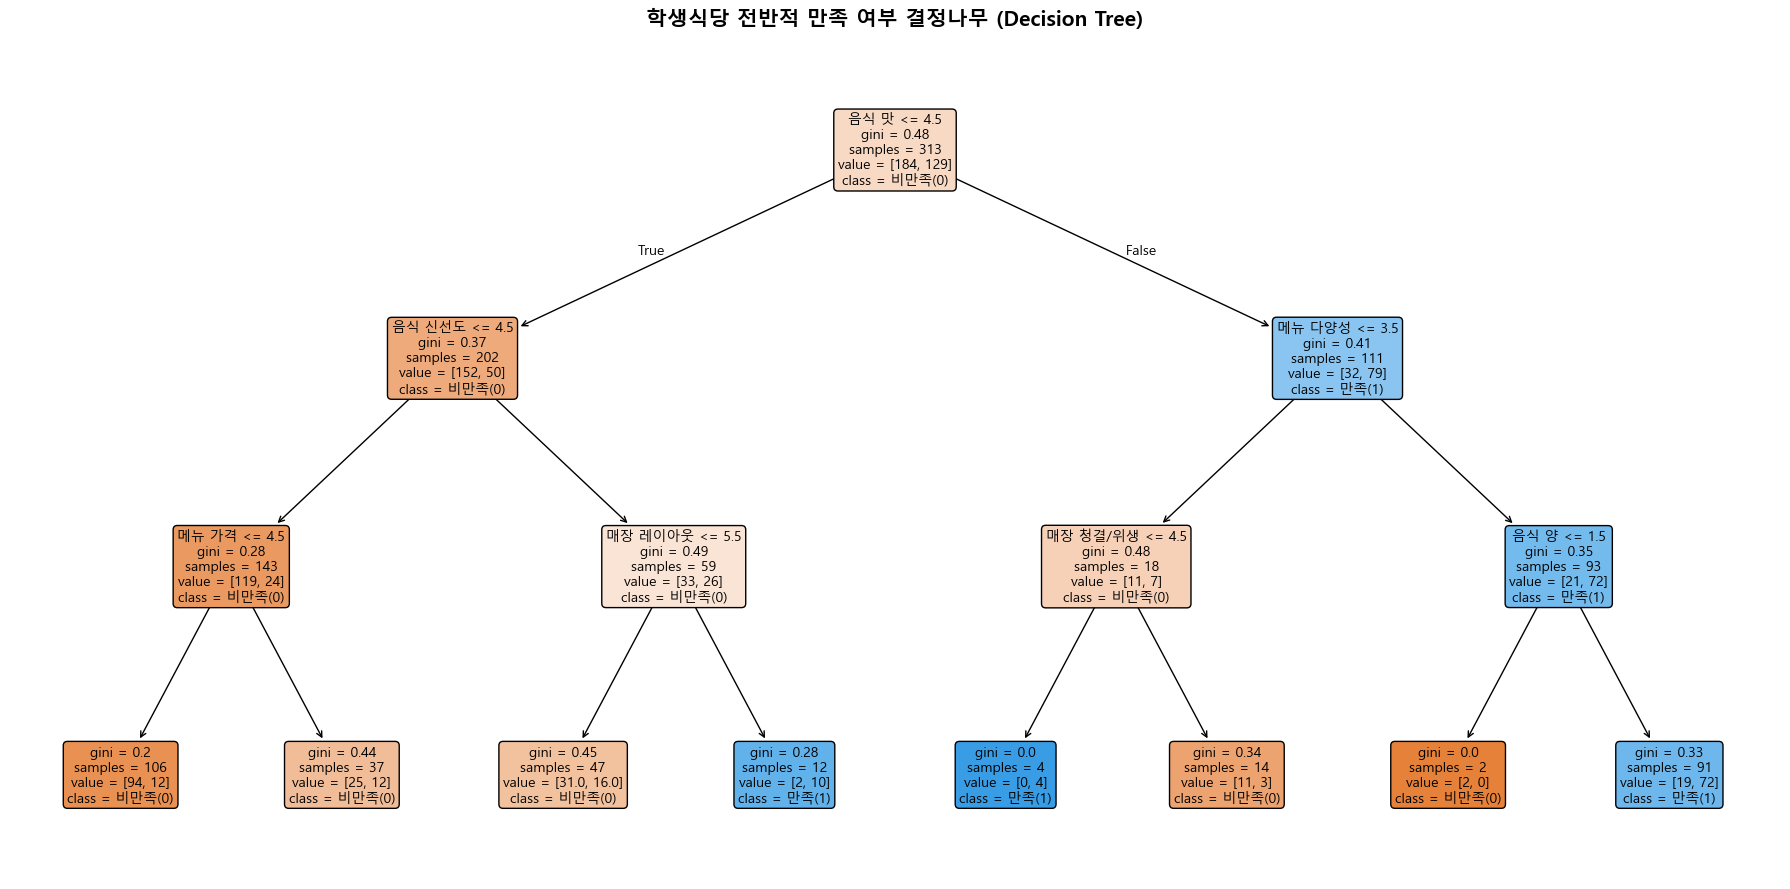

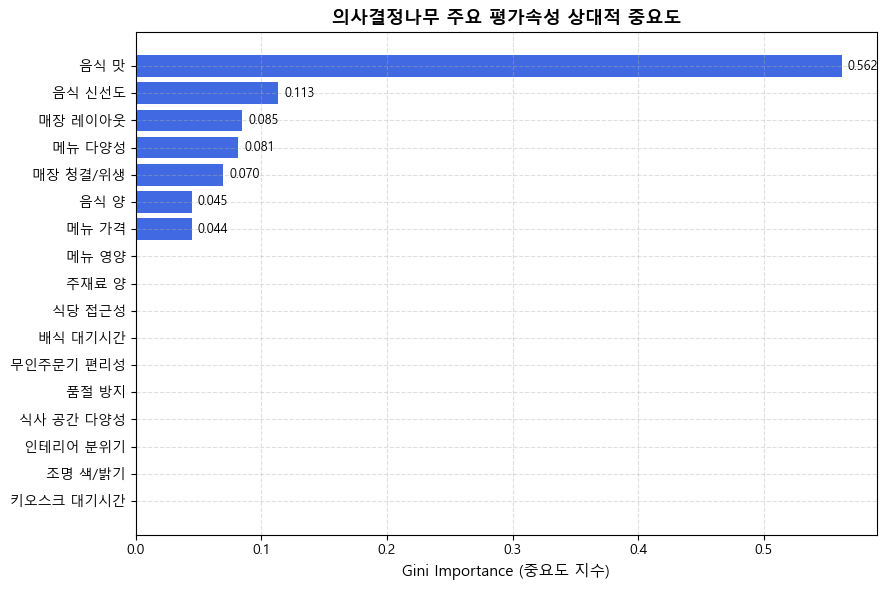

In [ ]:
# 의사결정나무 모델 학습
dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(df[sat_cols], df['sat_binary'])

# [시각화 1-1] 의사결정나무 구조 트리 차트
plt.figure(figsize=(18, 9))
plot_tree(
    dt_model,
    feature_names=attr_names,
    class_names=['비만족(0)', '만족(1)'],
    filled=True,
    rounded=True,
    fontsize=10,
    precision=2
)
plt.title("학생식당 전반적 만족 여부 결정나무 (Decision Tree)", fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('Decision_Tree_Structure.png', dpi=300)
plt.show()

# [시각화 1-2] 특성 중요도 (Feature Importance) 막대그래프
importance_df = pd.DataFrame({
    '속성': attr_names,
    '중요도': dt_model.feature_importances_
}).sort_values('중요도', ascending=True)

plt.figure(figsize=(9, 6))
bars = plt.barh(importance_df['속성'], importance_df['중요도'], color='royalblue')
plt.title("의사결정나무 주요 평가속성 상대적 중요도", fontsize=13, fontweight='bold')
plt.xlabel("Gini Importance (중요도 지수)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4)

# 수치 라벨링
for bar in bars:
    width = bar.get_width()
    if width > 0:
        plt.text(width + 0.005, bar.get_y() + bar.get_height()/2, f'{width:.3f}', 
                 va='center', fontsize=9)

plt.tight_layout()
plt.savefig('Decision_Tree_Feature_Importance.png', dpi=300)
plt.show()

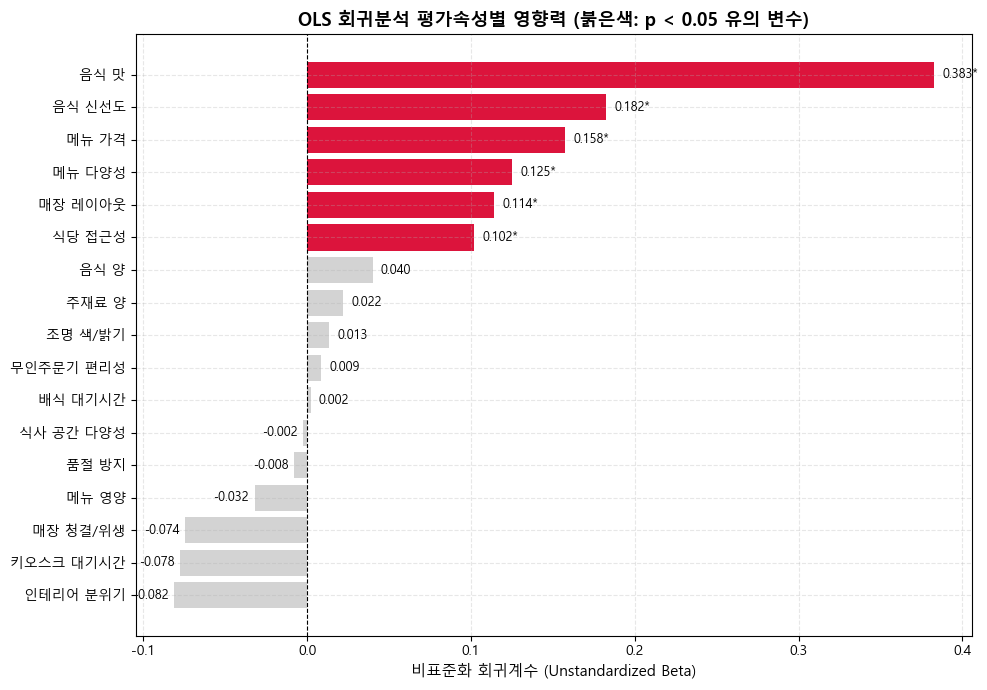

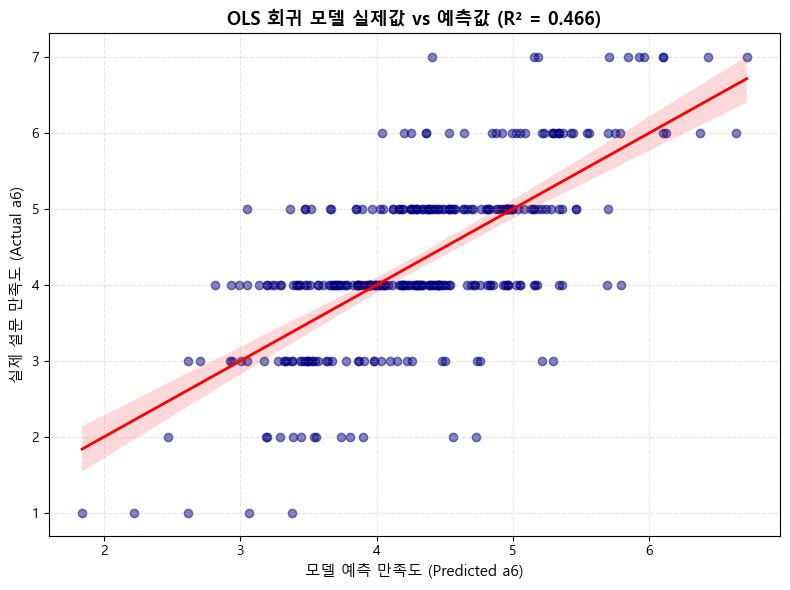

In [ ]:
# OLS 다중회귀 적합 (종속변수: 연속형 a6)
X_ols = sm.add_constant(df[sat_cols])
y_ols = df['a6']
ols_model = sm.OLS(y_ols, X_ols).fit()

# [시각화 2-1] OLS 회귀계수 및 p-value 유의성 강조 차트
ols_results = pd.DataFrame({
    '속성': attr_names,
    '계수': ols_model.params[1:],
    'p_value': ols_model.pvalues[1:]
}).sort_values('계수', ascending=True)

# p-value 0.05 미만 유의 변수 색상 구분
colors = ['crimson' if p < 0.05 else 'lightgrey' for p in ols_results['p_value']]

plt.figure(figsize=(10, 7))
bars = plt.barh(ols_results['속성'], ols_results['계수'], color=colors)
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.title("OLS 회귀분석 평가속성별 영향력 (붉은색: p < 0.05 유의 변수)", fontsize=13, fontweight='bold')
plt.xlabel("비표준화 회귀계수 (Unstandardized Beta)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.3)

for bar, p_val in zip(bars, ols_results['p_value']):
    width = bar.get_width()
    label = f'{width:.3f}*' if p_val < 0.05 else f'{width:.3f}'
    offset = 0.005 if width >= 0 else -0.025
    plt.text(width + offset, bar.get_y() + bar.get_height()/2, label, va='center', fontsize=9)

plt.tight_layout()
plt.savefig('OLS_Regression_Coefficients.png', dpi=300)
plt.show()

# [시각화 2-2] 실제 만족도 vs 예측 만족도 회귀 산점도
df['a6_pred'] = ols_model.predict(X_ols)

plt.figure(figsize=(8, 6))
sns.regplot(data=df, x='a6_pred', y='a6', scatter_kws={'alpha': 0.5, 'color': 'navy'}, line_kws={'color': 'red', 'linewidth': 2})
plt.title(f"OLS 회귀 모델 실제값 vs 예측값 (R² = {ols_model.rsquared:.3f})", fontsize=13, fontweight='bold')
plt.xlabel("모델 예측 만족도 (Predicted a6)", fontsize=11)
plt.ylabel("실제 설문 만족도 (Actual a6)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('OLS_Actual_vs_Predicted.png', dpi=300)
plt.show()

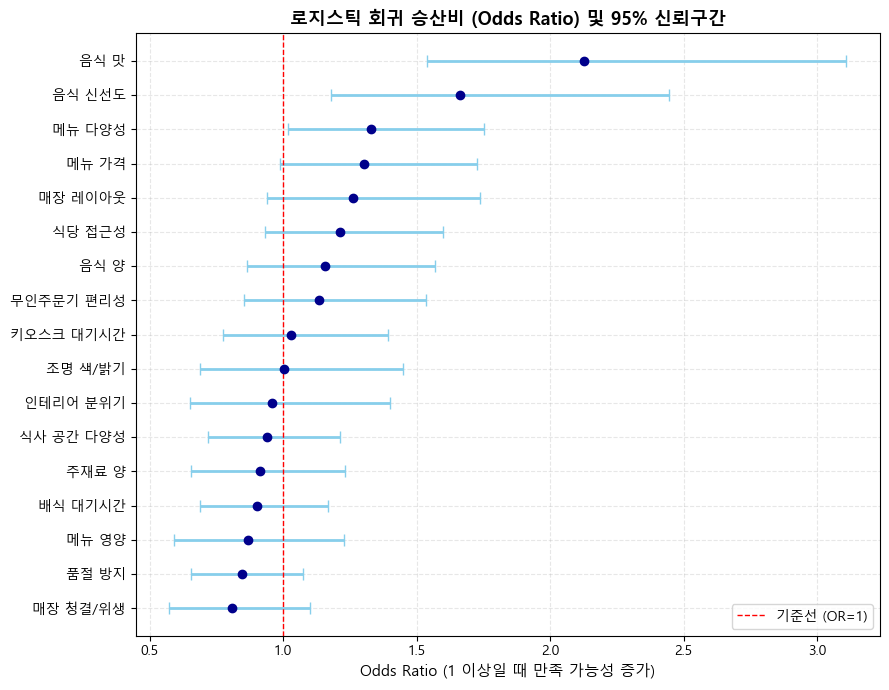

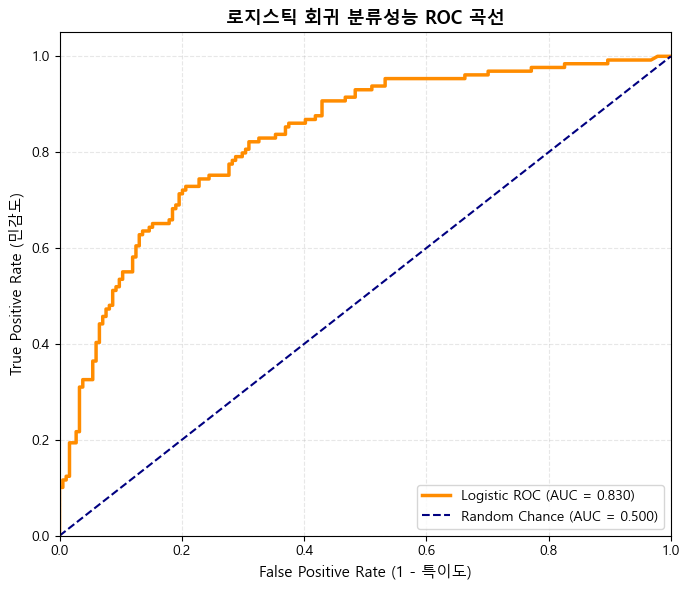

In [ ]:
from sklearn.metrics import roc_curve, auc

# 로지스틱 회귀 적합
clf = LogisticRegression(random_state=42, max_iter=1000)
clf.fit(df[sat_cols], df['sat_binary'])

# [시각화 3-1] 로지스틱 승산비(Odds Ratio) 및 95% 신뢰구간 차트
coefs = clf.coef_[0]
odds_ratios = np.exp(coefs)

# statsmodels를 통한 신뢰구간 산출
logit_sm = sm.Logit(df['sat_binary'], sm.add_constant(df[sat_cols])).fit(disp=False)
conf_int = np.exp(logit_sm.conf_int().iloc[1:])  # 상수항 제외

or_df = pd.DataFrame({
    '속성': attr_names,
    'OR': odds_ratios,
    'CI_lower': conf_int[0].values,
    'CI_upper': conf_int[1].values
}).sort_values('OR', ascending=True)

plt.figure(figsize=(9, 7))
y_pos = np.arange(len(or_df))
plt.errorbar(
    or_df['OR'], y_pos, 
    xerr=[or_df['OR'] - or_df['CI_lower'], or_df['CI_upper'] - or_df['OR']], 
    fmt='o', color='darkblue', ecolor='skyblue', elinewidth=2, capsize=4
)
plt.axvline(x=1.0, color='red', linestyle='--', linewidth=1, label='기준선 (OR=1)')
plt.yticks(y_pos, or_df['속성'])
plt.title("로지스틱 회귀 승산비 (Odds Ratio) 및 95% 신뢰구간", fontsize=13, fontweight='bold')
plt.xlabel("Odds Ratio (1 이상일 때 만족 가능성 증가)", fontsize=11)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('Logistic_Odds_Ratio_CI.png', dpi=300)
plt.show()

# [시각화 3-2] ROC Curve (Receiver Operating Characteristic)
y_probs = clf.predict_proba(df[sat_cols])[:, 1]
fpr, tpr, _ = roc_curve(df['sat_binary'], y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'Logistic ROC (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - 특이도)', fontsize=11)
plt.ylabel('True Positive Rate (민감도)', fontsize=11)
plt.title('로지스틱 회귀 분류성능 ROC 곡선', fontsize=13, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('Logistic_ROC_Curve.png', dpi=300)
plt.show()


In [ ]:
# ==========================================
# 9. 교차분석 (Cross-tabulation & Chi-square Test) 및 시각화
# ==========================================
print("\n" + "="*65)
print("[Step 9] 교차표 생성, 카이제곱($\chi^2$) 검정 및 시각화")
print("="*65)

def run_crosstab_analysis(
    data, row_var, col_var, 
    row_name=None, col_name=None,
    row_order=None, col_order=None,
    colors=None, save_filename=None, figsize=(8, 5)
):
    """
    범주형 두 변수에 대한 교차표(빈도+비율), 카이제곱 검정, 누적 막대그래프를 한 번에 실행하는 함수
    """
    row_name = row_name or row_var
    col_name = col_name or col_var
    
    # 결측치 제거 후 교차표(원빈도) 생성
    sub_df = data[[row_var, col_var]].dropna()
    ct = pd.crosstab(sub_df[row_var], sub_df[col_var])
    
    # 행/열 순서 지정 시 재정렬
    if row_order:
        ct = ct.reindex([r for r in row_order if r in ct.index])
    if col_order:
        ct = ct.reindex(columns=[c for c in col_order if c in ct.columns])
        
    # 행 기준 백분율(%) 계산
    ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
    
    # 1) 출력용 교차표 (빈도 + 행 비율 결합)
    ct_display = pd.DataFrame(index=ct.index, columns=ct.columns)
    for r in ct.index:
        for c in ct.columns:
            ct_display.loc[r, c] = f"{ct.loc[r, c]}명 ({ct_pct.loc[r, c]:.1f}%)"
    ct_display['합계 (N)'] = ct.sum(axis=1).apply(lambda x: f"{x}명 (100.0%)")
    
    # 전체 합계 행 추가
    total_counts = ct.sum(axis=0)
    total_n = total_counts.sum()
    total_row = {c: f"{total_counts[c]}명 ({total_counts[c]/total_n*100:.1f}%)" for c in ct.columns}
    total_row['합계 (N)'] = f"{total_n}명 (100.0%)"
    ct_display.loc['전체 합계'] = total_row
    
    print(f"\n▶ [교차분석] {row_name} × {col_name} (유효표본 N={total_n})")
    print("-" * 65)
    print(ct_display.to_string())
    
    # 2) 피어슨 카이제곱 독립성 검정 (Pearson's Chi-square Test)
    chi2, p_val, dof, expected = stats.chi2_contingency(ct)
    
    # 효과크기: Cramér's V
    min_dim = min(ct.shape) - 1
    cramers_v = np.sqrt(chi2 / (total_n * min_dim)) if min_dim > 0 else 0.0
    
    # 기대빈도 5 미만 셀 비율 확인 (카이제곱 검정 가정 체크)
    low_exp_ratio = (expected < 5).sum() / expected.size * 100
    
    sig_str = "유의미한 차이 있음 (p < 0.05) ★" if p_val < 0.05 else "통계적으로 유의하지 않음 (p >= 0.05)"
    print("-" * 65)
    print(f"· 카이제곱 통계량 (χ²): {chi2:.3f} (자유도 df = {dof})")
    print(f"· 유의확률 (p-value)   : {p_val:.4f} → {sig_str}")
    print(f"· 효과크기 (Cramér's V): {cramers_v:.3f}")
    if low_exp_ratio > 20:
        print(f"  [주의] 기대빈도 5 미만 셀이 {low_exp_ratio:.1f}%입니다. 범주 통합 또는 Fisher 정확검정을 고려하세요.")
        
    # 3) 100% 누적 막대그래프 시각화
    fig, ax = plt.subplots(figsize=figsize)
    palette = colors if colors else sns.color_palette("Set2", n_colors=len(ct.columns))
    
    ct_pct.plot(kind='bar', stacked=True, ax=ax, color=palette, width=0.55, edgecolor='white', linewidth=1.2)
    
    # 막대 내부에 비율(%) 및 인원수(n) 라벨 표기
    for i, r in enumerate(ct.index):
        cum_height = 0
        for c in ct.columns:
            pct = ct_pct.loc[r, c]
            cnt = ct.loc[r, c]
            if pct >= 6.0:  # 글자 겹침 방지를 위해 6% 이상 구간만 라벨 표시
                ax.text(
                    i, cum_height + pct / 2,
                    f"{pct:.1f}%\n({cnt}명)",
                    ha='center', va='center', fontsize=9.5, fontweight='bold', color='#222222'
                )
            cum_height += pct
            
    # X축 라벨에 집단별 표본수 표시
    x_labels = [f"{r}\n(n={ct.loc[r].sum()})" for r in ct.index]
    ax.set_xticklabels(x_labels, rotation=0, fontsize=10.5)
    ax.set_ylim(0, 105)
    ax.set_ylabel("비율 (%)", fontsize=11)
    ax.set_xlabel(row_name, fontsize=11, fontweight='bold', labelpad=8)
    
    p_text = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"
    ax.set_title(
        f"{row_name}별 {col_name} 분포\n(χ² = {chi2:.2f}, df = {dof}, {p_text})",
        fontsize=13, fontweight='bold', pad=14
    )
    ax.legend(title=col_name, bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    sns.despine(top=True, right=True)
    
    plt.tight_layout()
    if save_filename:
        plt.savefig(save_filename, dpi=300, bbox_inches='tight')
    plt.show()
    
    return ct, ct_pct, {'chi2': chi2, 'p_value': p_val, 'dof': dof, 'cramers_v': cramers_v}


[Step 9] 교차표 생성, 카이제곱($\chi^2$) 검정 및 시각화



▶ [교차분석] 세분시장 군집 × 전반적 만족 여부 (유효표본 N=313)
-----------------------------------------------------------------
sat_label         만족(5점 이상)    비만족(4점 이하)         합계 (N)
cluster_label                                           
실속형             52명 (65.0%)   28명 (35.0%)   80명 (100.0%)
편의형             58명 (50.4%)   57명 (49.6%)  115명 (100.0%)
품질형             19명 (16.1%)   99명 (83.9%)  118명 (100.0%)
전체 합계          129명 (41.2%)  184명 (58.8%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 53.431 (자유도 df = 2)
· 유의확률 (p-value)   : 0.0000 → 유의미한 차이 있음 (p < 0.05) ★
· 효과크기 (Cramér's V): 0.413


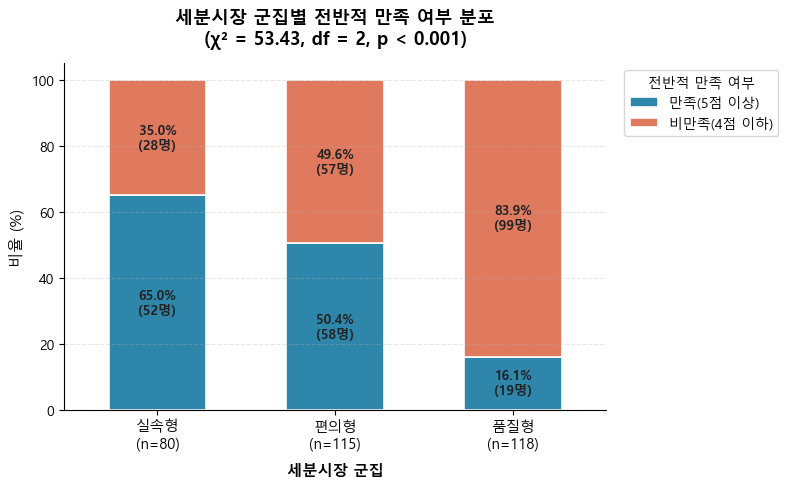

(sat_label      만족(5점 이상)  비만족(4점 이하)
 cluster_label                       
 실속형                   52          28
 편의형                   58          57
 품질형                   19          99,
 sat_label      만족(5점 이상)  비만족(4점 이하)
 cluster_label                       
 실속형            65.000000   35.000000
 편의형            50.434783   49.565217
 품질형            16.101695   83.898305,
 {'chi2': np.float64(53.43124984942448),
  'p_value': np.float64(2.497764648310928e-12),
  'dof': 2,
  'cramers_v': np.float64(0.4131668773371272)})

In [ ]:
# [분석 1] 군집 유형별 전반적 만족 여부 교차분석
run_crosstab_analysis(
    data=df,
    row_var='cluster_label',
    col_var='sat_label',
    row_name='세분시장 군집',
    col_name='전반적 만족 여부',
    row_order=['실속형', '편의형', '품질형'],
    col_order=['만족(5점 이상)', '비만족(4점 이하)'],
    colors=['#2E86AB', '#E07A5F'],
    save_filename='Crosstab_Cluster_Satisfaction.png'
)


▶ [교차분석] 세분시장 군집 × 성별 (유효표본 N=313)
-----------------------------------------------------------------
gen_label                남성            여성         합계 (N)
cluster_label                                           
실속형             36명 (45.0%)   44명 (55.0%)   80명 (100.0%)
편의형             44명 (38.3%)   71명 (61.7%)  115명 (100.0%)
품질형             47명 (39.8%)   71명 (60.2%)  118명 (100.0%)
전체 합계          127명 (40.6%)  186명 (59.4%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 0.932 (자유도 df = 2)
· 유의확률 (p-value)   : 0.6274 → 통계적으로 유의하지 않음 (p >= 0.05)
· 효과크기 (Cramér's V): 0.055


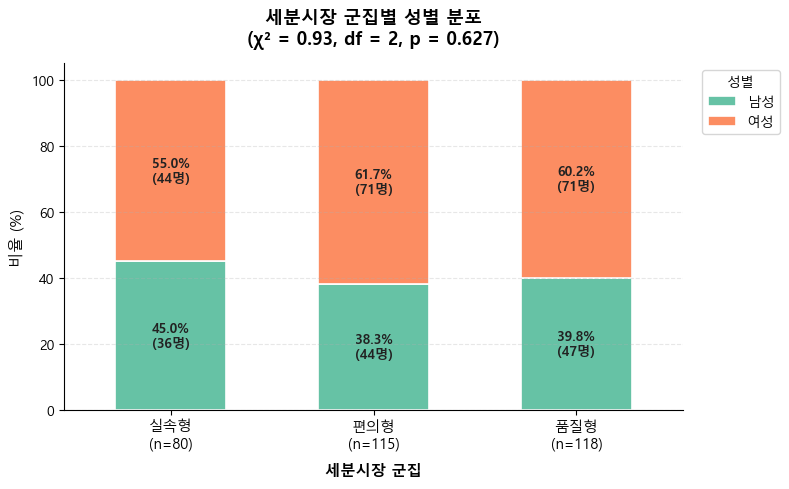


▶ [교차분석] 세분시장 군집 × 학년 구분 (유효표본 N=313)
-----------------------------------------------------------------
grade_grp       저학년(1-2학년)    고학년(3-4학년)         합계 (N)
cluster_label                                          
실속형            17명 (21.2%)   63명 (78.8%)   80명 (100.0%)
편의형            17명 (14.8%)   98명 (85.2%)  115명 (100.0%)
품질형            19명 (16.1%)   99명 (83.9%)  118명 (100.0%)
전체 합계          53명 (16.9%)  260명 (83.1%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 1.496 (자유도 df = 2)
· 유의확률 (p-value)   : 0.4733 → 통계적으로 유의하지 않음 (p >= 0.05)
· 효과크기 (Cramér's V): 0.069


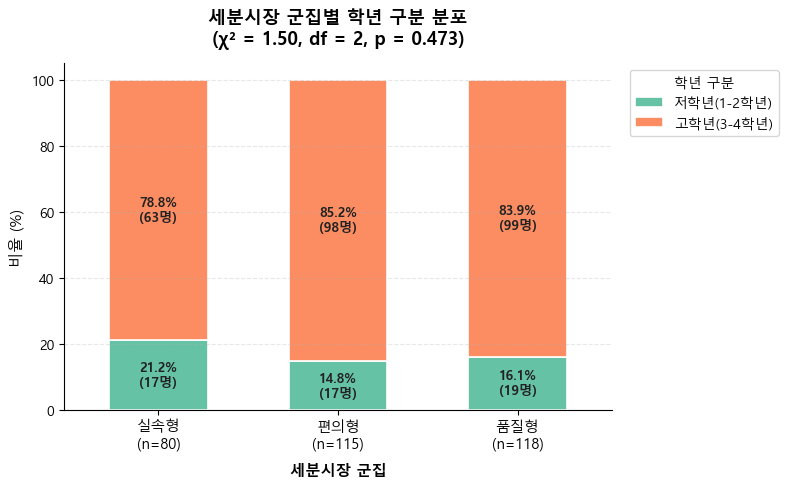


▶ [교차분석] 세분시장 군집 × 주거 형태 (유효표본 N=313)
-----------------------------------------------------------------
housing_grp           기숙사            자취            통학         기타         합계 (N)
cluster_label                                                                  
실속형             3명 (3.8%)   35명 (43.8%)   42명 (52.5%)  0명 (0.0%)   80명 (100.0%)
편의형             7명 (6.1%)   45명 (39.1%)   63명 (54.8%)  0명 (0.0%)  115명 (100.0%)
품질형             6명 (5.1%)   45명 (38.1%)   66명 (55.9%)  1명 (0.8%)  118명 (100.0%)
전체 합계          16명 (5.1%)  125명 (39.9%)  171명 (54.6%)  1명 (0.3%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 2.666 (자유도 df = 6)
· 유의확률 (p-value)   : 0.8494 → 통계적으로 유의하지 않음 (p >= 0.05)
· 효과크기 (Cramér's V): 0.065
  [주의] 기대빈도 5 미만 셀이 33.3%입니다. 범주 통합 또는 Fisher 정확검정을 고려하세요.


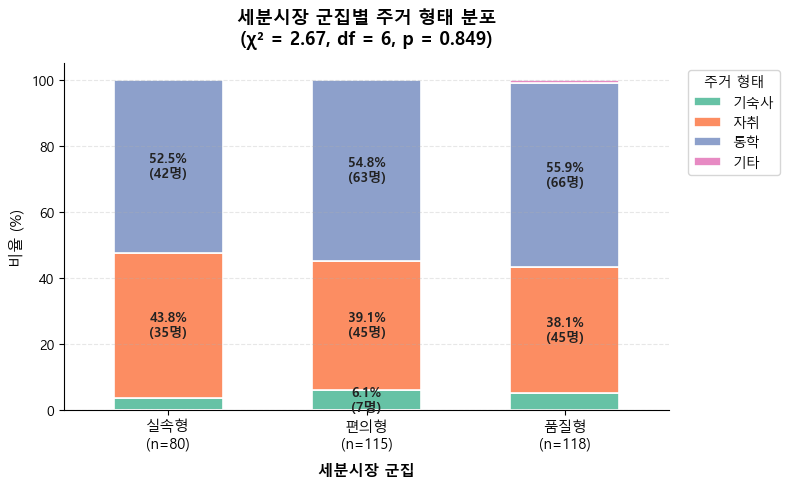


▶ [교차분석] 세분시장 군집 × 월 평균 용돈 (유효표본 N=313)
-----------------------------------------------------------------
allowance_grp      30만원 이하       31~50만원       51만원 이상         합계 (N)
cluster_label                                                        
실속형            17명 (21.2%)   29명 (36.2%)   34명 (42.5%)   80명 (100.0%)
편의형            20명 (17.4%)   46명 (40.0%)   49명 (42.6%)  115명 (100.0%)
품질형            21명 (17.8%)   37명 (31.4%)   60명 (50.8%)  118명 (100.0%)
전체 합계          58명 (18.5%)  112명 (35.8%)  143명 (45.7%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 2.761 (자유도 df = 4)
· 유의확률 (p-value)   : 0.5986 → 통계적으로 유의하지 않음 (p >= 0.05)
· 효과크기 (Cramér's V): 0.066


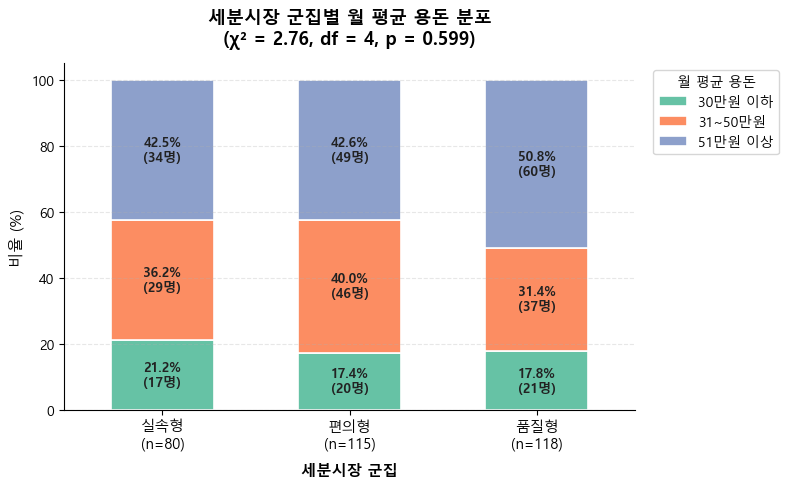


▶ [교차분석] 세분시장 군집 × 통학 시간 (유효표본 N=313)
-----------------------------------------------------------------
commute_grp          30분 미만   30분~1시간 미만       1시간 이상         합계 (N)
cluster_label                                                       
실속형             39명 (48.8%)  23명 (28.7%)  18명 (22.5%)   80명 (100.0%)
편의형             55명 (47.8%)  34명 (29.6%)  26명 (22.6%)  115명 (100.0%)
품질형             56명 (47.5%)  31명 (26.3%)  31명 (26.3%)  118명 (100.0%)
전체 합계          150명 (47.9%)  88명 (28.1%)  75명 (24.0%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 0.679 (자유도 df = 4)
· 유의확률 (p-value)   : 0.9539 → 통계적으로 유의하지 않음 (p >= 0.05)
· 효과크기 (Cramér's V): 0.033


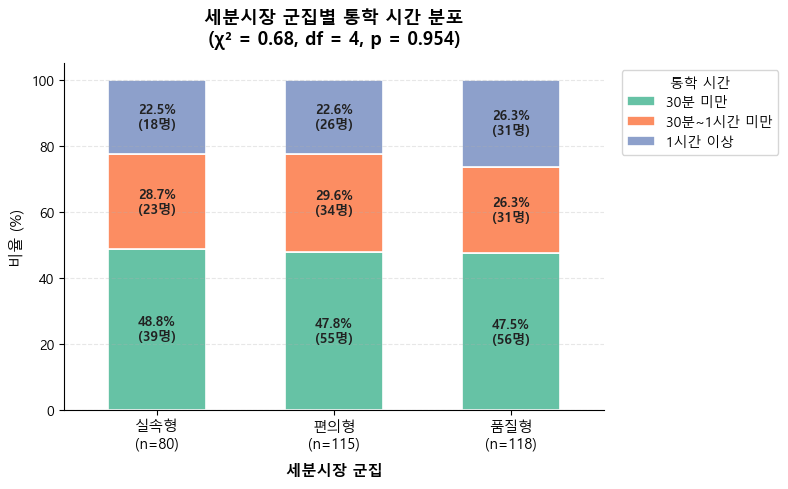


[요약표] 군집별 인구통계학적 특성 카이제곱 검정 결과 일람
       비교 변수  χ² 통계량  자유도(df)  p-value  Cramér's V 유의성(α=0.05)
     군집 × 성별   0.932        2   0.6274       0.055     유의하지 않음
  군집 × 학년 구분   1.496        2   0.4733       0.069     유의하지 않음
  군집 × 주거 형태   2.666        6   0.8494       0.065     유의하지 않음
군집 × 월 평균 용돈   2.761        4   0.5986       0.066     유의하지 않음
  군집 × 통학 시간   0.679        4   0.9539       0.033     유의하지 않음


In [ ]:
# [분석 2] 세분시장 군집별 인구통계학적 특성 일괄 프로파일링
demo_vars = {
    'gen_label': ('성별', ['남성', '여성']),
    'grade_grp': ('학년 구분', ['저학년(1-2학년)', '고학년(3-4학년)']),
    'housing_grp': ('주거 형태', ['기숙사', '자취', '통학', '기타']),
    'allowance_grp': ('월 평균 용돈', ['30만원 이하', '31~50만원', '51만원 이상']),
    'commute_grp': ('통학 시간', ['30분 미만', '30분~1시간 미만', '1시간 이상'])
}

summary_results = []

for var, (label, order) in demo_vars.items():
    _, _, res = run_crosstab_analysis(
        data=df,
        row_var='cluster_label',
        col_var=var,
        row_name='세분시장 군집',
        col_name=label,
        row_order=['실속형', '편의형', '품질형'],
        col_order=order,
        save_filename=f'Crosstab_Cluster_{var}.png'
    )
    summary_results.append({
        '비교 변수': f"군집 × {label}",
        'χ² 통계량': round(res['chi2'], 3),
        '자유도(df)': res['dof'],
        'p-value': round(res['p_value'], 4),
        "Cramér's V": round(res['cramers_v'], 3),
        '유의성(α=0.05)': '유의함 (*)' if res['p_value'] < 0.05 else '유의하지 않음'
    })

print("\n" + "="*65)
print("[요약표] 군집별 인구통계학적 특성 카이제곱 검정 결과 일람")
print("="*65)
print(pd.DataFrame(summary_results).to_string(index=False))


▶ [교차분석] 성별 × 전반적 만족 여부 (유효표본 N=313)
-----------------------------------------------------------------
sat_label     만족(5점 이상)    비만족(4점 이하)         합계 (N)
gen_label                                           
남성          62명 (48.8%)   65명 (51.2%)  127명 (100.0%)
여성          67명 (36.0%)  119명 (64.0%)  186명 (100.0%)
전체 합계      129명 (41.2%)  184명 (58.8%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 4.587 (자유도 df = 1)
· 유의확률 (p-value)   : 0.0322 → 유의미한 차이 있음 (p < 0.05) ★
· 효과크기 (Cramér's V): 0.121


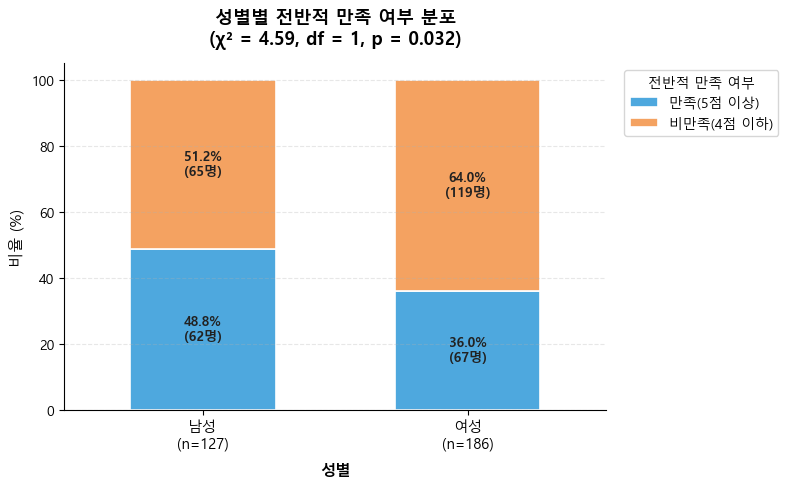


▶ [교차분석] 학년 구분 × 전반적 만족 여부 (유효표본 N=313)
-----------------------------------------------------------------
sat_label      만족(5점 이상)    비만족(4점 이하)         합계 (N)
grade_grp                                            
저학년(1-2학년)   29명 (54.7%)   24명 (45.3%)   53명 (100.0%)
고학년(3-4학년)  100명 (38.5%)  160명 (61.5%)  260명 (100.0%)
전체 합계       129명 (41.2%)  184명 (58.8%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 4.154 (자유도 df = 1)
· 유의확률 (p-value)   : 0.0415 → 유의미한 차이 있음 (p < 0.05) ★
· 효과크기 (Cramér's V): 0.115


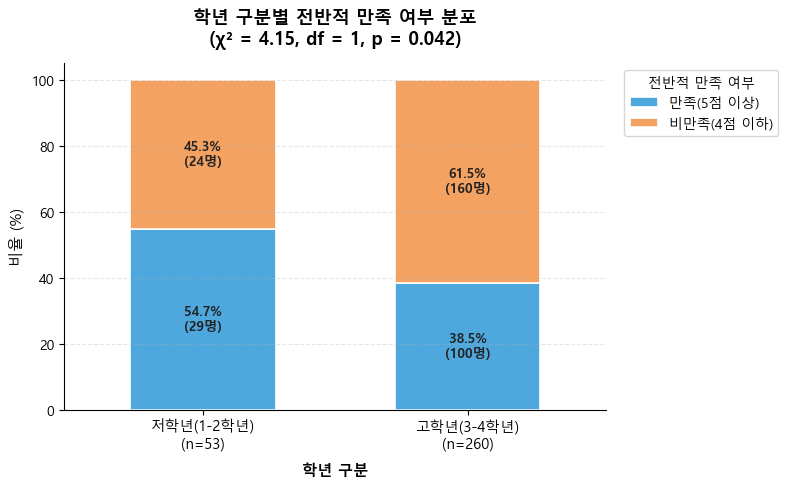


▶ [교차분석] 주거 형태 × 전반적 만족 여부 (유효표본 N=313)
-----------------------------------------------------------------
sat_label       만족(5점 이상)    비만족(4점 이하)         합계 (N)
housing_grp                                           
기숙사           10명 (62.5%)    6명 (37.5%)   16명 (100.0%)
자취            58명 (46.4%)   67명 (53.6%)  125명 (100.0%)
통학            60명 (35.1%)  111명 (64.9%)  171명 (100.0%)
기타            1명 (100.0%)     0명 (0.0%)    1명 (100.0%)
전체 합계        129명 (41.2%)  184명 (58.8%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 8.455 (자유도 df = 3)
· 유의확률 (p-value)   : 0.0375 → 유의미한 차이 있음 (p < 0.05) ★
· 효과크기 (Cramér's V): 0.164
  [주의] 기대빈도 5 미만 셀이 25.0%입니다. 범주 통합 또는 Fisher 정확검정을 고려하세요.


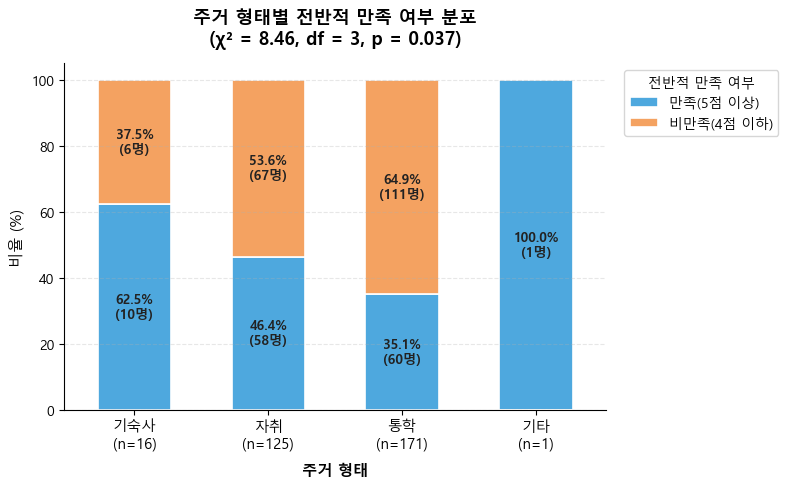


▶ [교차분석] 월 평균 용돈 × 전반적 만족 여부 (유효표본 N=313)
-----------------------------------------------------------------
sat_label         만족(5점 이상)    비만족(4점 이하)         합계 (N)
allowance_grp                                           
30만원 이하         20명 (34.5%)   38명 (65.5%)   58명 (100.0%)
31~50만원         52명 (46.4%)   60명 (53.6%)  112명 (100.0%)
51만원 이상         57명 (39.9%)   86명 (60.1%)  143명 (100.0%)
전체 합계          129명 (41.2%)  184명 (58.8%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 2.450 (자유도 df = 2)
· 유의확률 (p-value)   : 0.2938 → 통계적으로 유의하지 않음 (p >= 0.05)
· 효과크기 (Cramér's V): 0.088


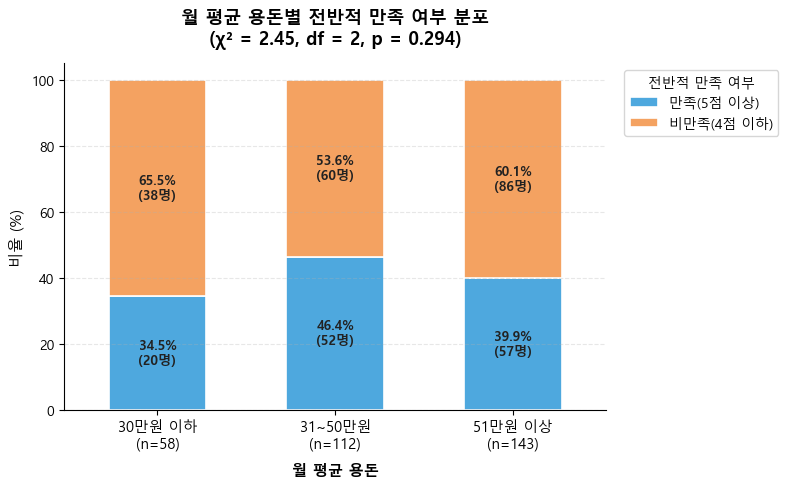


▶ [교차분석] 통학 시간 × 전반적 만족 여부 (유효표본 N=313)
-----------------------------------------------------------------
sat_label       만족(5점 이상)    비만족(4점 이하)         합계 (N)
commute_grp                                           
30분 미만        71명 (47.3%)   79명 (52.7%)  150명 (100.0%)
30분~1시간 미만    34명 (38.6%)   54명 (61.4%)   88명 (100.0%)
1시간 이상        24명 (32.0%)   51명 (68.0%)   75명 (100.0%)
전체 합계        129명 (41.2%)  184명 (58.8%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 5.188 (자유도 df = 2)
· 유의확률 (p-value)   : 0.0747 → 통계적으로 유의하지 않음 (p >= 0.05)
· 효과크기 (Cramér's V): 0.129


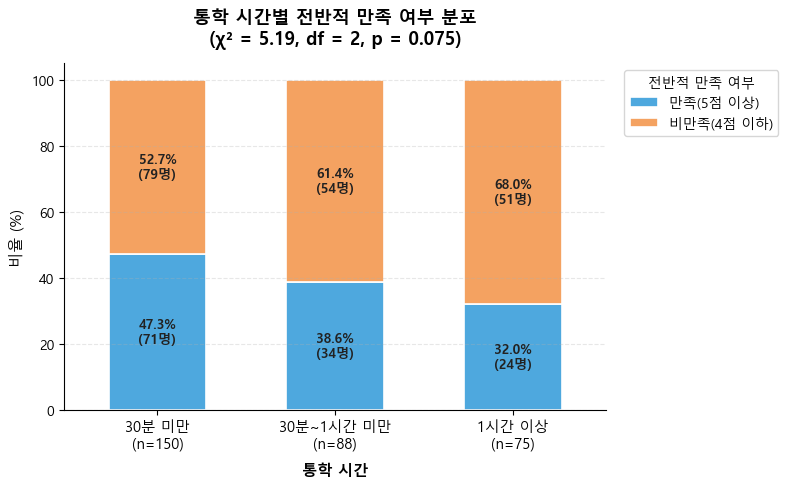

In [ ]:
# [분석 3] 인구통계학적 특성별 전반적 만족 여부 교차분석
for var, (label, order) in demo_vars.items():
    run_crosstab_analysis(
        data=df,
        row_var=var,
        col_var='sat_label',
        row_name=label,
        col_name='전반적 만족 여부',
        row_order=order,
        col_order=['만족(5점 이상)', '비만족(4점 이하)'],
        colors=['#4EA8DE', '#F4A261'],
        save_filename=f'Crosstab_{var}_Satisfaction.png'
    )


▶ [교차분석] 세분시장 군집 × 푸드코트 전환 의향 (유효표본 N=313)
-----------------------------------------------------------------
foodcourt_grp     찬성(5~7점)       보통(4점)      반대(1~3점)         합계 (N)
cluster_label                                                       
실속형            26명 (32.5%)   9명 (11.2%)   45명 (56.2%)   80명 (100.0%)
편의형            36명 (31.3%)  20명 (17.4%)   59명 (51.3%)  115명 (100.0%)
품질형            29명 (24.6%)  27명 (22.9%)   62명 (52.5%)  118명 (100.0%)
전체 합계          91명 (29.1%)  56명 (17.9%)  166명 (53.0%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 5.198 (자유도 df = 4)
· 유의확률 (p-value)   : 0.2676 → 통계적으로 유의하지 않음 (p >= 0.05)
· 효과크기 (Cramér's V): 0.091


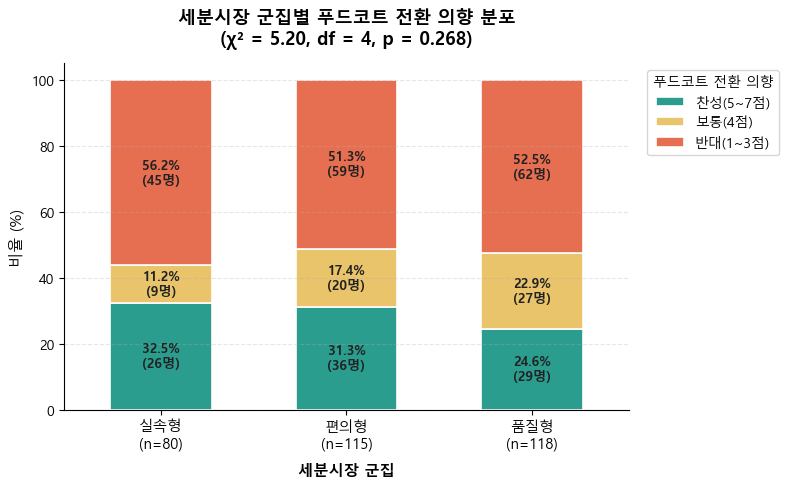


▶ [교차분석] 전반적 만족 여부 × 푸드코트 전환 의향 (유효표본 N=313)
-----------------------------------------------------------------
foodcourt_grp     찬성(5~7점)       보통(4점)      반대(1~3점)         합계 (N)
sat_label                                                           
만족(5점 이상)      46명 (35.7%)  25명 (19.4%)   58명 (45.0%)  129명 (100.0%)
비만족(4점 이하)     45명 (24.5%)  31명 (16.8%)  108명 (58.7%)  184명 (100.0%)
전체 합계          91명 (29.1%)  56명 (17.9%)  166명 (53.0%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 6.242 (자유도 df = 2)
· 유의확률 (p-value)   : 0.0441 → 유의미한 차이 있음 (p < 0.05) ★
· 효과크기 (Cramér's V): 0.141


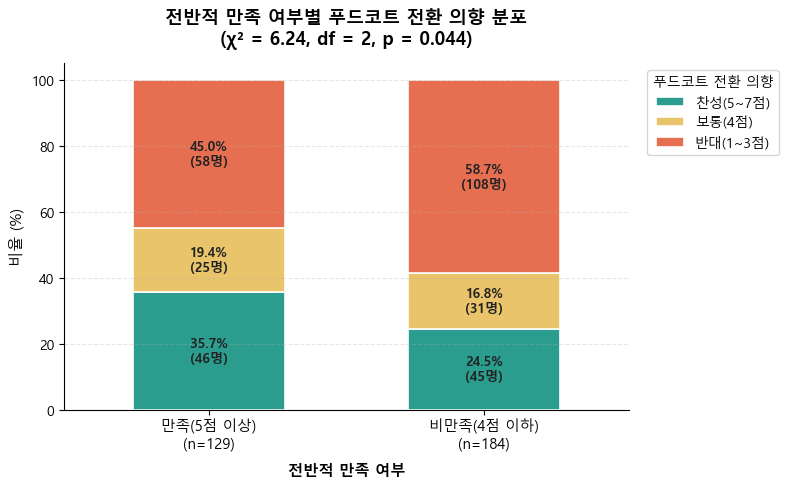


▶ [교차분석] 월 평균 용돈 × 푸드코트 전환 의향 (유효표본 N=313)
-----------------------------------------------------------------
foodcourt_grp     찬성(5~7점)       보통(4점)      반대(1~3점)         합계 (N)
allowance_grp                                                       
30만원 이하        20명 (34.5%)  14명 (24.1%)   24명 (41.4%)   58명 (100.0%)
31~50만원        31명 (27.7%)  18명 (16.1%)   63명 (56.2%)  112명 (100.0%)
51만원 이상        40명 (28.0%)  24명 (16.8%)   79명 (55.2%)  143명 (100.0%)
전체 합계          91명 (29.1%)  56명 (17.9%)  166명 (53.0%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 4.124 (자유도 df = 4)
· 유의확률 (p-value)   : 0.3894 → 통계적으로 유의하지 않음 (p >= 0.05)
· 효과크기 (Cramér's V): 0.081


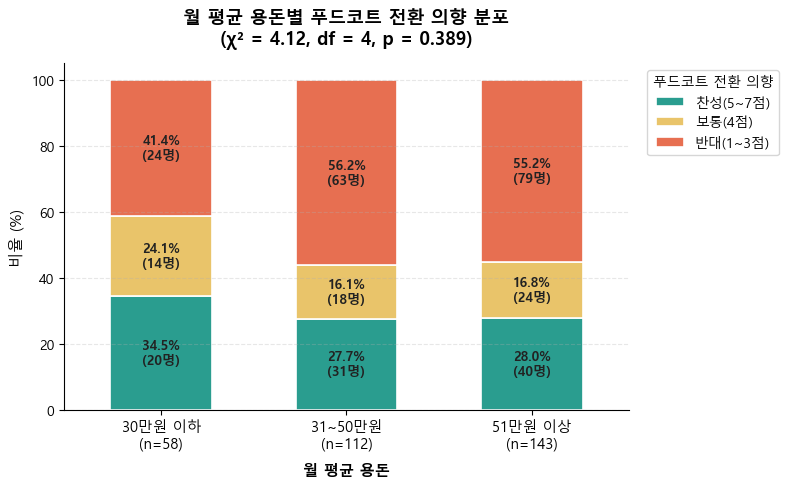


▶ [교차분석] 주거 형태 × 푸드코트 전환 의향 (유효표본 N=312)
-----------------------------------------------------------------
foodcourt_grp     찬성(5~7점)       보통(4점)      반대(1~3점)         합계 (N)
housing_grp                                                         
기숙사            10명 (62.5%)    1명 (6.2%)    5명 (31.2%)   16명 (100.0%)
자취             29명 (23.2%)  23명 (18.4%)   73명 (58.4%)  125명 (100.0%)
통학             52명 (30.4%)  32명 (18.7%)   87명 (50.9%)  171명 (100.0%)
전체 합계          91명 (29.2%)  56명 (17.9%)  165명 (52.9%)  312명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 11.267 (자유도 df = 4)
· 유의확률 (p-value)   : 0.0237 → 유의미한 차이 있음 (p < 0.05) ★
· 효과크기 (Cramér's V): 0.134
  [주의] 기대빈도 5 미만 셀이 22.2%입니다. 범주 통합 또는 Fisher 정확검정을 고려하세요.


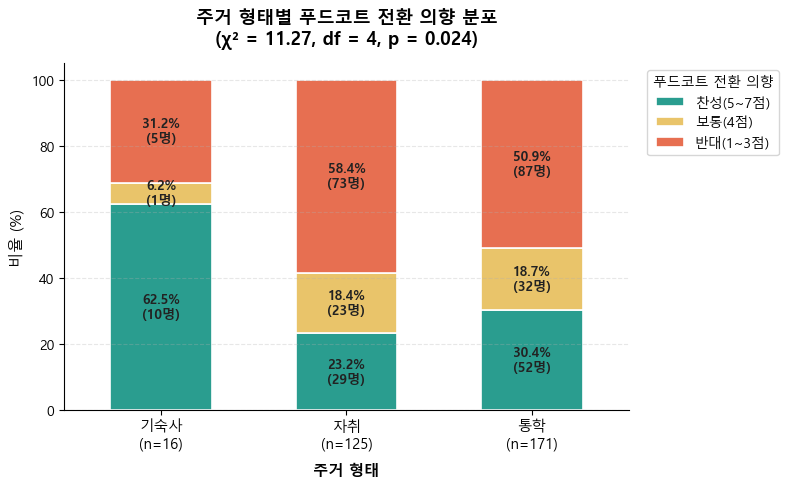


▶ [교차분석] 학년 구분 × 푸드코트 전환 의향 (유효표본 N=313)
-----------------------------------------------------------------
foodcourt_grp     찬성(5~7점)       보통(4점)      반대(1~3점)         합계 (N)
grade_grp                                                           
저학년(1-2학년)     15명 (28.3%)  11명 (20.8%)   27명 (50.9%)   53명 (100.0%)
고학년(3-4학년)     76명 (29.2%)  45명 (17.3%)  139명 (53.5%)  260명 (100.0%)
전체 합계          91명 (29.1%)  56명 (17.9%)  166명 (53.0%)  313명 (100.0%)
-----------------------------------------------------------------
· 카이제곱 통계량 (χ²): 0.358 (자유도 df = 2)
· 유의확률 (p-value)   : 0.8361 → 통계적으로 유의하지 않음 (p >= 0.05)
· 효과크기 (Cramér's V): 0.034


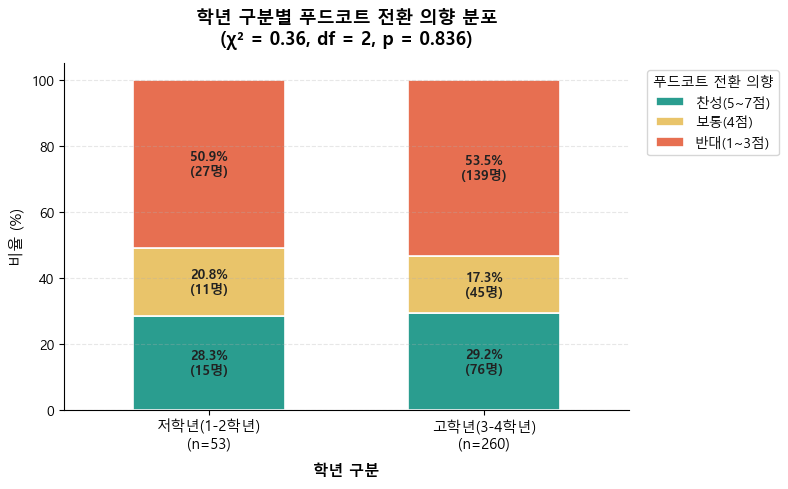


[요약표] 푸드코트 전환 의향 관련 카이제곱(χ²) 검정 결과 일람
            비교 변수  χ² 통계량  자유도(df)  p-value  Cramér's V 유의성(α=0.05)
  세분시장 군집 × 전환 의향   5.198        4   0.2676       0.091     유의하지 않음
전반적 만족 여부 × 전환 의향   6.242        2   0.0441       0.141     유의함 (*)
  월 평균 용돈 × 전환 의향   4.124        4   0.3894       0.081     유의하지 않음
    주거 형태 × 전환 의향  11.267        4   0.0237       0.134     유의함 (*)
    학년 구분 × 전환 의향   0.358        2   0.8361       0.034     유의하지 않음


In [ ]:
# ==========================================
# [추가 분석] 푸드코트 전환 의향 범주화 및 핵심 변수 교차분석
# ==========================================

# 1. 푸드코트 전환 의향 변수 범주화 (7점 척도 기준)
# sat_label과 통일성을 맞추려면 2범주(5점 이상 vs 4점 이하), 
# 중립층(4점) 규모를 따로 보고 싶다면 3범주(반대/보통/찬성)를 사용하세요.
target_col = 'c11'  # 실제 푸드코트 전환 의향 컬럼명으로 수정

# [옵션 A] 3범주 매핑 (추천: 반대/중립/찬성 비율 파악 용이)
df['foodcourt_grp'] = pd.cut(
    df[target_col],
    bins=[0, 3, 4, 7],
    labels=['반대(1~3점)', '보통(4점)', '찬성(5~7점)']
)
fc_order = ['찬성(5~7점)', '보통(4점)', '반대(1~3점)']
fc_colors = ['#2A9D8F', '#E9C46A', '#E76F51']

# [옵션 B] 2범주 매핑 (표본 수가 부족해 기대빈도 경고가 뜰 경우 사용)
# df['foodcourt_grp'] = np.where(df[target_col] >= 5, '찬성(5점 이상)', '유보/반대(4점 이하)')
# fc_order = ['찬성(5점 이상)', '유보/반대(4점 이하)']
# fc_colors = ['#2A9D8F', '#E76F51']

# 2. 교차 매핑할 핵심 변수 정의 (행 변수: 비교 집단, 열 변수: 푸드코트 전환 의향)
fc_target_vars = {
    'cluster_label': ('세분시장 군집', ['실속형', '편의형', '품질형']),
    'sat_label': ('전반적 만족 여부', ['만족(5점 이상)', '비만족(4점 이하)']),
    'allowance_grp': ('월 평균 용돈', ['30만원 이하', '31~50만원', '51만원 이상']),
    'housing_grp': ('주거 형태', ['기숙사', '자취', '통학']),  # '기타' 소수 범주 제외 시 검정 안정성 상승
    'grade_grp': ('학년 구분', ['저학년(1-2학년)', '고학년(3-4학년)'])
}

fc_summary = []

for var, (label, row_ord) in fc_target_vars.items():
    # 주거형태의 '기타'처럼 극소수 범주로 인한 카이제곱 왜곡 방지 필터링
    plot_df = df[df[var].isin(row_ord)]
    
    _, _, res = run_crosstab_analysis(
        data=plot_df,
        row_var=var,
        col_var='foodcourt_grp',
        row_name=label,
        col_name='푸드코트 전환 의향',
        row_order=row_ord,
        col_order=fc_order,
        colors=fc_colors,
        save_filename=f'Crosstab_{var}_Foodcourt.png'
    )
    
    fc_summary.append({
        '비교 변수': f"{label} × 전환 의향",
        'χ² 통계량': round(res['chi2'], 3),
        '자유도(df)': res['dof'],
        'p-value': round(res['p_value'], 4),
        "Cramér's V": round(res['cramers_v'], 3),
        '유의성(α=0.05)': '유의함 (*)' if res['p_value'] < 0.05 else '유의하지 않음'
    })

print("\n" + "="*65)
print("[요약표] 푸드코트 전환 의향 관련 카이제곱(χ²) 검정 결과 일람")
print("="*65)
print(pd.DataFrame(fc_summary).to_string(index=False))

In [ ]:
# [추가] 군집(cluster_label) x 인구통계/라이프스타일 교차표 및 카이제곱 검정
demo_vars = ['gen_label', 'grade_grp', 'housing_grp', 'allowance_grp', 'commute_grp']
demo_names = ['성별', '학년군', '주거형태', '월평균 용돈', '통학시간']

for col, name in zip(demo_vars, demo_names):
    ct_cnt = pd.crosstab(df[col], df['cluster_label'])[['실속형', '품질형', '편의형']]
    ct_pct = pd.crosstab(df[col], df['cluster_label'], normalize='index')[['실속형', '품질형', '편의형']] * 100
    chi2, p_val, dof, _ = stats.chi2_contingency(ct_cnt)
    
    print(f"\n[{name} x 세분시장 교차표] (chi2 = {chi2:.3f}, p-value = {p_val:.4f})")
    summary_ct = ct_cnt.astype(str) + "명 (" + ct_pct.round(1).astype(str) + "%)"
    print(summary_ct)


[성별 x 세분시장 교차표] (chi2 = 0.932, p-value = 0.6274)
cluster_label          실속형          품질형          편의형
gen_label                                           
남성             36명 (28.3%)  47명 (37.0%)  44명 (34.6%)
여성             44명 (23.7%)  71명 (38.2%)  71명 (38.2%)

[학년군 x 세분시장 교차표] (chi2 = 1.496, p-value = 0.4733)
cluster_label          실속형          품질형          편의형
grade_grp                                           
저학년(1-2학년)     17명 (32.1%)  19명 (35.8%)  17명 (32.1%)
고학년(3-4학년)     63명 (24.2%)  99명 (38.1%)  98명 (37.7%)

[주거형태 x 세분시장 교차표] (chi2 = 2.666, p-value = 0.8494)
cluster_label          실속형          품질형          편의형
housing_grp                                         
기숙사             3명 (18.8%)   6명 (37.5%)   7명 (43.8%)
기타               0명 (0.0%)  1명 (100.0%)    0명 (0.0%)
자취             35명 (28.0%)  45명 (36.0%)  45명 (36.0%)
통학             42명 (24.6%)  66명 (38.6%)  63명 (36.8%)

[월평균 용돈 x 세분시장 교차표] (chi2 = 2.761, p-value = 0.5986)
cluster_label          실속형          품질형          편의